# Walmart Hurricane Analytics - Team Notebook

DS2002 Midterm, Fall 2026 · Ethan, Steve, Henry

Hurricane Helene made landfall in Florida's Big Bend on the night of **Sep 26, 2024**.
This notebook cleans five messy Walmart data files, pulls real weather from the Open-Meteo API, and answers five questions about what sold, where, and whether the signal is real.

Run with **Restart and Run All**. Data lives in `../data/`. The weather API needs no key.

1. Setup and profile
2. Cleaning pipeline and decision log
3. SKU consolidation
4. Weather API and join
5. Q1 Demand surge
6. Q2 SKU consolidation
7. Q3 Weather correlation
8. Q4 Stores and geography
9. Q5 Signal or artifact
10. Recommendations

## 1. Setup and profile

In [1]:
import sqlite3
import time

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option('display.max_colwidth', None)
plt.rcParams['figure.dpi'] = 110

def profile(df, name):
    out = pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'nulls': df.isna().sum(),
        'null_pct': (df.isna().mean() * 100).round(2),
        'distinct': df.nunique(),
        'example': df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
    })
    print(f'{name}: {df.shape[0]:,} rows x {df.shape[1]} columns')
    return out

In [2]:
profile(pd.read_csv('../data/walmart_transactions.csv', na_values=['', 'NULL', 'N/A', 'NaN', 'nan']), 'walmart_transactions')

walmart_transactions: 25,562 rows x 8 columns


,dtype,nulls,null_pct,distinct,example
transaction_id,object,0,0.00,25532,TXN012636
store_id,object,0,0.00,60,FL-710
timestamp,object,886,3.47,23952,2024-09-24T09:48:13
sku,object,0,0.00,45,PNUTBTR-16
product_name,object,0,0.00,63,PEANUT BUTTER
category,object,0,0.00,37,Grocery
quantity,int64,0,0.00,11,1
unit_price,object,0,0.00,3668,3.15


Five worst problems from the profile:

- `store_id` has 60 distinct values for 12 stores (`FL-239`, `FL_239`, `FL239`, `fl-239`, `' FL-239'`)
- `timestamp` mixes 5 formats and 886 values are blank, `NULL`, `N/A`, `NaN` or `nan`
- `unit_price` is text, some values start with `$` or a space
- 45 SKUs for 20 real products (strawberry Pop-Tarts alone has 4 SKUs)
- `category` has 37 spellings of 10 categories, plus 130 negative quantities and 30 duplicate rows

## 2. Cleaning pipeline

Every decision is logged with the number of rows it touched. Times are local store time.

In [3]:
import pandas as pd
import numpy as np

DATA = '../data/'
NA = ['', 'NULL', 'N/A', 'NaN', 'nan']

decisions = []
def log(step, decision, rows):
    decisions.append({'step': step, 'decision': decision, 'rows_touched': int(rows)})


def clean_store_id(s):
    s = s.astype(str).str.strip().str.upper().str.replace('_', '-')
    return s.str.replace(r'^FL(\d{3})$', r'FL-\1', regex=True)

def parse_timestamps(s):
    formats = ['%Y-%m-%d %H:%M:%S', '%Y-%m-%dT%H:%M:%S', '%m/%d/%Y %H:%M', '%m-%d-%Y %H:%M:%S', '%d-%b-%Y %H:%M']
    out = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns]')
    for f in formats:
        out = out.combine_first(pd.to_datetime(s, format=f, errors='coerce'))
    return out

CATEGORY_MAP = {
    'emergency': 'Emergency', 'emergency supplies': 'Emergency',
    'grocery': 'Grocery', 'groceries': 'Grocery',
    'electronics': 'Electronics',
    'entertainment': 'Entertainment', 'games & entertainment': 'Entertainment',
    'household': 'Household', 'household essentials': 'Household',
    'baby': 'Baby', 'baby products': 'Baby',
    'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast',
    'alcohol': 'Alcohol', 'alcoholic beverages': 'Alcohol',
    'snacks': 'Snacks',
    'health': 'Health', 'health & wellness': 'Health',
}

def clean_category(s):
    return s.str.strip().str.lower().map(CATEGORY_MAP)


def clean_transactions(raw):
    df = raw.copy()

    n = len(df)
    df = df.drop_duplicates()
    log('duplicates', 'dropped exact duplicate rows (same transaction_id and every other column)', n - len(df))
    assert df['transaction_id'].is_unique

    new = clean_store_id(df['store_id'])
    log('store_id', 'strip, uppercase, _ -> -, FL239 -> FL-239', (new != df['store_id']).sum())
    df['store_id'] = new

    price = df['unit_price'].astype(str).str.strip().str.lstrip('$')
    log('unit_price', 'removed $ and spaces, converted text to float', (price != df['unit_price']).sum())
    df['unit_price'] = pd.to_numeric(price, errors='raise')

    df['quantity'] = df['quantity'].astype(int)
    neg = df['quantity'] < 0
    log('quantity', 'dropped negative quantities (returns, not demand)', neg.sum())
    df = df[~neg]

    df['timestamp'] = parse_timestamps(df['timestamp'])
    missing = df['timestamp'].isna()
    log('timestamp', 'parsed 5 formats as local store time; dropped rows with no timestamp (blank/NULL/N/A/NaN)', missing.sum())
    df = df[~missing]

    cat = clean_category(df['category'])
    assert cat.notna().all()
    log('category', 'mapped 37 spellings onto 10 categories (names match the inventory db)', (cat != df['category']).sum())
    df['category'] = cat

    df['product_name'] = df['product_name'].str.strip()
    df['revenue'] = df['quantity'] * df['unit_price']
    return df.reset_index(drop=True)


def clean_stores(raw):
    df = raw.copy()
    df['store_id'] = clean_store_id(df['store_id'])
    n = len(df)
    df = df.drop_duplicates('store_id')
    log('stores', 'dropped duplicate store rows after fixing store_id (FL239, FL_287)', n - len(df))
    log('stores', 'state Florida / Fla. -> FL, stripped region', (df['state'] != 'FL').sum())
    df['state'] = 'FL'
    df['region'] = df['region'].str.strip()
    tlh = df['latitude'].isna()
    df.loc[df['store_id'] == 'FL-619', ['latitude', 'longitude']] = [30.4383, -84.2807]
    log('stores', 'filled missing lat/lon for FL-619 Tallahassee with city center coordinates', tlh.sum())
    df['tz'] = np.where(df['store_id'] == 'FL-710', 'America/Chicago', 'America/New_York')
    return df.reset_index(drop=True)


raw_tx = pd.read_csv(DATA + 'walmart_transactions.csv', dtype=str, keep_default_na=False)
raw_stores = pd.read_csv(DATA + 'store_locations.csv', na_values=NA)

tx = clean_transactions(raw_tx)
stores = clean_stores(raw_stores)

print('transactions:', len(raw_tx), '->', len(tx), f'({len(raw_tx) - len(tx)} removed)')
print('stores:', len(raw_stores), '->', len(stores))
print('store ids in tx:', tx['store_id'].nunique(), '| all join to store file:', tx['store_id'].isin(stores['store_id']).all())
print('date range:', tx['timestamp'].min(), 'to', tx['timestamp'].max())

transactions: 25562 -> 24521 (1041 removed)
stores: 14 -> 12
store ids in tx: 12 | all join to store file: True
date range: 2024-09-01 06:01:15 to 2024-09-30 22:57:47


In [4]:
pd.DataFrame(decisions)

,step,decision,rows_touched
0,duplicates,dropped exact duplicate rows (same transaction_id and every other column),30
1,store_id,"strip, uppercase, _ -> -, FL239 -> FL-239",4345
2,unit_price,"removed $ and spaces, converted text to float",4329
3,quantity,"dropped negative quantities (returns, not demand)",130
4,timestamp,parsed 5 formats as local store time; dropped rows with no timestamp (blank/NULL/N/A/NaN),881
5,category,mapped 37 spellings onto 10 categories (names match the inventory db),18009
6,stores,"dropped duplicate store rows after fixing store_id (FL239, FL_287)",2
7,stores,"state Florida / Fla. -> FL, stripped region",3
8,stores,filled missing lat/lon for FL-619 Tallahassee with city center coordinates,1


## 3. SKU consolidation

Each catalog SKU is mapped to one canonical product by keyword on its product name. The assert fails if a SKU matches zero or two products.

In [5]:
import re

catalog = pd.read_csv(DATA + 'product_catalog.csv', na_values=NA)

PRODUCT_KEYWORDS = [
    ('pop-?tart', 'Pop-Tarts Strawberry'),
    ('water', 'Bottled Water 24-Pack'),
    ('batter', 'AA Batteries 4-Pack'),
    ('flashlight', 'LED Flashlight'),
    ('beer', 'Light Beer 24-Pack'),
    ('monopoly', 'Monopoly Board Game'),
    ('playing cards', 'Playing Cards'),
    ('roku|streaming', 'Roku Streaming Stick'),
    ('soup', 'Canned Soup'),
    ('bread', 'White Bread'),
    ('peanut', 'Peanut Butter'),
    ('candle', 'Emergency Candles'),
    ('first.aid', 'First Aid Kit'),
    ('charger', 'Portable Phone Charger'),
    ('chips', 'Chips Variety Pack'),
    ('paper towel', 'Paper Towels'),
    ('toilet', 'Toilet Paper 12-Roll'),
    ('diaper', 'Baby Diapers Size 3'),
    ('formula', 'Baby Formula'),
    ('tarp', 'Heavy Duty Tarp'),
]

def canonical_product(name):
    name = name.lower()
    hits = [p for kw, p in PRODUCT_KEYWORDS if re.search(kw, name)]
    assert len(hits) == 1, (name, hits)
    return hits[0]

def build_sku_map(catalog):
    m = catalog[['sku', 'product_name', 'category']].copy()
    m['product'] = m['product_name'].apply(canonical_product)
    m['category'] = clean_category(m['category'])
    return m

sku_map = build_sku_map(catalog)

print('categories per product:', sku_map.groupby('product')['category'].nunique().max())

before = tx['sku'].nunique()
tx['product'] = tx['sku'].map(sku_map.set_index('sku')['product'])
assert tx['product'].notna().all()

wrong_cat = (tx['category'] != tx['sku'].map(sku_map.set_index('sku')['category'])).sum()
log('sku', 'mapped 45 SKUs to 20 canonical products by keyword on the catalog name', len(tx))
print('transaction rows whose category disagrees with the catalog:', wrong_cat)

groups = sku_map.groupby('product')['sku'].apply(list)
print('distinct SKUs:', before, '-> canonical products:', tx['product'].nunique())
print('largest groups:', groups[groups.str.len() == groups.str.len().max()].to_dict())

sku_map.sort_values(['product', 'sku'])

categories per product: 1
transaction rows whose category disagrees with the catalog: 0
distinct SKUs: 45 -> canonical products: 20
largest groups: {'Pop-Tarts Strawberry': ['PT-12', 'SKU#459812', 'POPTART-STRAW', 'PT_STRAWBERRY']}


,sku,product_name,category,product
8,BAT-AA4,AA Batteries 4-Pack,Emergency,AA Batteries 4-Pack
7,BATT-100,BATTERIES AA 4PK,Emergency,AA Batteries 4-Pack
9,BATT_AA_4PK,AA Batteries 4-Pack,Emergency,AA Batteries 4-Pack
39,DIAP-S3,Baby Diapers - Size 3,Baby,Baby Diapers Size 3
40,DIAPERS-3,DIAPERS SZ 3,Baby,Baby Diapers Size 3
42,BABYFORMULA,Baby Formula,Baby,Baby Formula
41,BFORM-01,Infant Formula,Baby,Baby Formula
5,WATER24PK,Bottled Water 24-Pack,Emergency,Bottled Water 24-Pack
4,WTR-24,BOTTLED WATER 24PK,Emergency,Bottled Water 24-Pack
6,WTR_24PK,Water - 24 Pack,Emergency,Bottled Water 24-Pack


## 4. Weather API and join

Source: Open-Meteo historical weather API, `https://archive-api.open-meteo.com/v1/archive` (no key).

The API returns hourly data in **GMT**. Sales are in **local store time**: Eastern for 11 stores, Central for Pensacola (FL-710).
We fetch one extra day on each side, convert each hour to the store's own timezone, then roll up to local calendar days, so a 9pm Eastern hour counts on the right day.

In [6]:
import requests
import time

BASE_URL = 'https://archive-api.open-meteo.com/v1/archive'

def get_with_retries(params, retries=4):
    for attempt in range(retries):
        try:
            r = requests.get(BASE_URL, params=params, timeout=30)
            if r.status_code == 200:
                return r.json()
            print('got status', r.status_code, 'retrying')
        except requests.RequestException as e:
            print('request failed:', e)
        time.sleep(2 ** attempt)
    raise RuntimeError(f'weather API failed after {retries} tries')


def fetch_weather(store, start='2024-09-01', end='2024-09-30'):
    params = {
        'latitude': store['latitude'], 'longitude': store['longitude'],
        'start_date': str((pd.Timestamp(start) - pd.Timedelta(days=1)).date()),
        'end_date': str((pd.Timestamp(end) + pd.Timedelta(days=1)).date()),
        'hourly': 'temperature_2m,precipitation,wind_speed_10m,wind_gusts_10m,pressure_msl',
        'temperature_unit': 'fahrenheit', 'wind_speed_unit': 'mph', 'precipitation_unit': 'inch',
    }
    data = get_with_retries(params)
    print('API timezone:', data['timezone'], '| utc offset:', data['utc_offset_seconds'])

    hourly = pd.DataFrame(data['hourly'])
    hourly['time_utc'] = pd.to_datetime(hourly['time']).dt.tz_localize('UTC')
    hourly['time_local'] = hourly['time_utc'].dt.tz_convert(store['tz'])
    hourly['date'] = hourly['time_local'].dt.date
    hourly = hourly[(hourly['date'] >= pd.Timestamp(start).date()) & (hourly['date'] <= pd.Timestamp(end).date())]

    daily = hourly.groupby('date').agg(
        hours=('time', 'size'),
        max_temp_f=('temperature_2m', 'max'),
        precip_in=('precipitation', 'sum'),
        max_wind_mph=('wind_speed_10m', 'max'),
        max_gust_mph=('wind_gusts_10m', 'max'),
        min_pressure_hpa=('pressure_msl', 'min'),
    ).reset_index()
    daily.insert(0, 'store_id', store['store_id'])
    daily['source'] = 'open-meteo: ' + BASE_URL
    return hourly, daily

In [7]:
weather_frames = []
for _, s in stores.iterrows():
    _, w = fetch_weather(s)
    weather_frames.append(w)
    time.sleep(0.5)
weather = pd.concat(weather_frames, ignore_index=True)

print('weather rows:', len(weather), '| stores:', weather['store_id'].nunique(), '| every day has 24 hours:', (weather['hours'] == 24).all())
weather.head()

API timezone: GMT | utc offset: 0


API timezone: GMT | utc offset: 0


API timezone: GMT | utc offset: 0


API timezone: GMT | utc offset: 0


API timezone: GMT | utc offset: 0


...

API timezone: GMT | utc offset: 0


API timezone: GMT | utc offset: 0


API timezone: GMT | utc offset: 0


weather rows: 360 | stores: 12 | every day has 24 hours: True


,store_id,date,hours,max_temp_f,precip_in,max_wind_mph,max_gust_mph,min_pressure_hpa,source
0,FL-239,2024-09-01,24,87.4,0.253,11.6,22.6,1012.8,open-meteo: https://archive-api.open-meteo.com/v1/archive
1,FL-239,2024-09-02,24,85.6,0.867,7.9,18.1,1013.0,open-meteo: https://archive-api.open-meteo.com/v1/archive
2,FL-239,2024-09-03,24,87.2,1.289,12.8,25.1,1014.3,open-meteo: https://archive-api.open-meteo.com/v1/archive
3,FL-239,2024-09-04,24,87.8,0.830,7.8,19.9,1016.5,open-meteo: https://archive-api.open-meteo.com/v1/archive
4,FL-239,2024-09-05,24,88.3,0.816,9.4,17.4,1014.8,open-meteo: https://archive-api.open-meteo.com/v1/archive


In [8]:
tx['date'] = tx['timestamp'].dt.normalize()
weather['date'] = pd.to_datetime(weather['date'])

store_day = (tx.groupby(['store_id', 'date'])
             .agg(transactions=('transaction_id', 'size'), units=('quantity', 'sum'), revenue=('revenue', 'sum'))
             .reset_index())

sw = store_day.merge(weather, on=['store_id', 'date'], how='inner', validate='one_to_one')
print('store-days in sales:', len(store_day), '| in weather:', len(weather), '| joined:', len(sw))
assert len(sw) == len(store_day) == len(weather) == stores.shape[0] * 30
sw.head()

store-days in sales: 360 | in weather: 360 | joined: 360


,store_id,date,transactions,units,revenue,hours,max_temp_f,precip_in,max_wind_mph,max_gust_mph,min_pressure_hpa,source
0,FL-078,2024-09-01,42,77,950.88,24,90.3,0.059,7.0,21.5,1011.9,open-meteo: https://archive-api.open-meteo.com/v1/archive
1,FL-078,2024-09-02,49,103,975.63,24,93.2,0.114,5.1,17.0,1011.9,open-meteo: https://archive-api.open-meteo.com/v1/archive
2,FL-078,2024-09-03,47,101,1034.53,24,90.9,0.315,10.1,22.1,1013.9,open-meteo: https://archive-api.open-meteo.com/v1/archive
3,FL-078,2024-09-04,46,84,879.15,24,87.8,0.614,9.5,21.3,1016.8,open-meteo: https://archive-api.open-meteo.com/v1/archive
4,FL-078,2024-09-05,43,90,1041.82,24,88.8,0.525,8.6,18.1,1015.4,open-meteo: https://archive-api.open-meteo.com/v1/archive


### Daily order volume

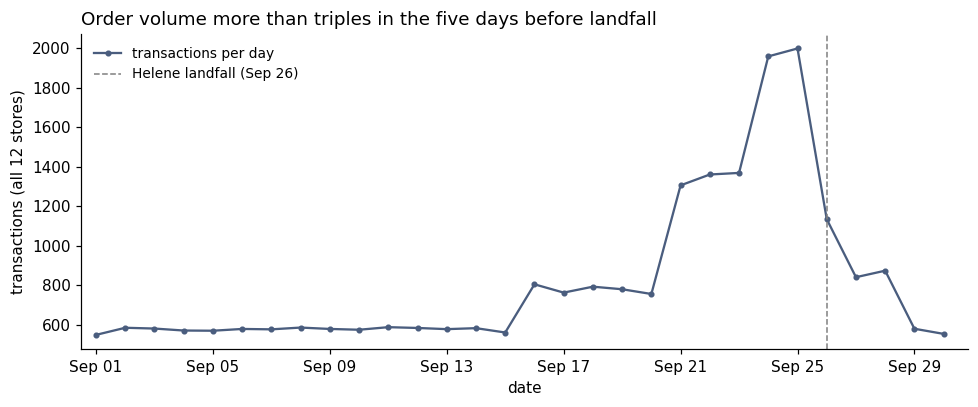

In [9]:
LANDFALL = pd.Timestamp('2024-09-26')
BASE_START, BASE_END = '2024-09-01', '2024-09-14'
COLORS = ['#b4553f', '#4a5d7e', '#7f9c6c', '#d9a441', '#8c6bb1']

daily_tx = tx.groupby('date').size()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(daily_tx.index, daily_tx.values, marker='o', ms=3, color='#4a5d7e', label='transactions per day')
ax.axvline(LANDFALL, ls='--', color='gray', lw=1, label='Helene landfall (Sep 26)')
ax.set_title('Order volume more than triples in the five days before landfall', loc='left', fontsize=12)
ax.set_xlabel('date')
ax.set_ylabel('transactions (all 12 stores)')
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=range(1, 31, 4)))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_xlim(pd.Timestamp('2024-08-31 12:00'), pd.Timestamp('2024-09-30 20:00'))
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

## 5. Q1 Demand surge

**Baseline window: Sep 1-14.** Daily volume is flat in that stretch (about 580 transactions a day) and it ends before the first step-up on Sep 16.
Using a window that includes Sep 16-20 would raise the baseline and understate the surge.

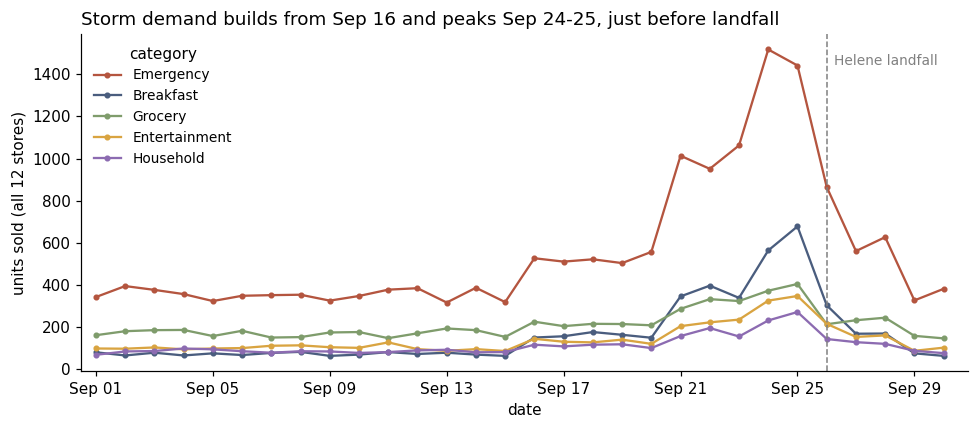

In [10]:
tx['date'] = tx['timestamp'].dt.normalize()

cat_daily = tx.pivot_table(index='date', columns='category', values='quantity', aggfunc='sum').fillna(0)
top5 = cat_daily.loc['2024-09-16':'2024-09-26'].sum().nlargest(5).index

fig, ax = plt.subplots(figsize=(9, 4))
for col, color in zip(top5, COLORS):
    ax.plot(cat_daily.index, cat_daily[col], marker='o', ms=3, color=color, label=col)
ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
ax.annotate('Helene landfall', xy=(LANDFALL + pd.Timedelta(hours=6), cat_daily[top5].max().max() * 0.95),
            fontsize=9, color='gray')
ax.set_title('Storm demand builds from Sep 16 and peaks Sep 24-25, just before landfall',
             loc='left', fontsize=12)
ax.set_xlabel('date')
ax.set_ylabel('units sold (all 12 stores)')
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=range(1, 31, 4)))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_xlim(pd.Timestamp('2024-08-31 12:00'), pd.Timestamp('2024-09-30 20:00'))
ax.legend(frameon=False, fontsize=9, title='category')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

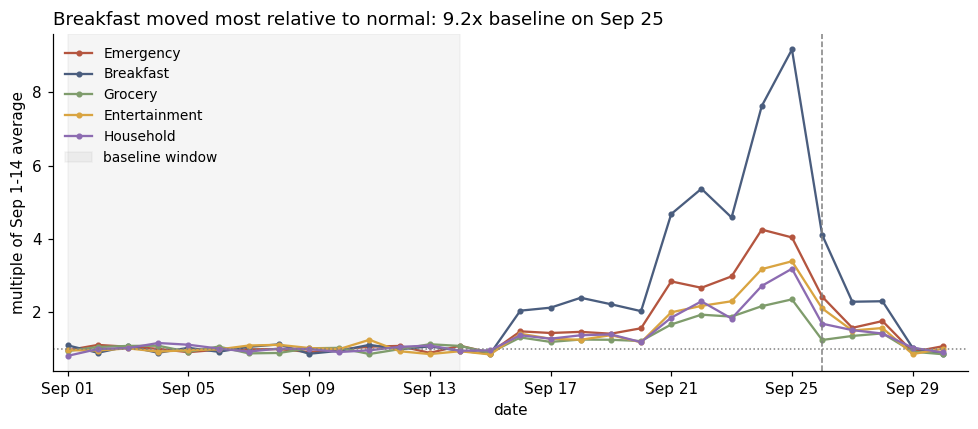

peak multiple by category (baseline Sep 1-14):
category
Breakfast        9.2
Emergency        4.3
Electronics      4.0
Health           3.5
Entertainment    3.4
Household        3.2
Alcohol          3.1
Grocery          2.4
Baby             2.0
Snacks           1.6
dtype: float64

top 5 products by peak multiple:
product
Pop-Tarts Strawberry     9.2
LED Flashlight           5.0
Bottled Water 24-Pack    4.6
Heavy Duty Tarp          4.5
Emergency Candles        4.4
dtype: float64


In [11]:
cat_base = cat_daily.loc[BASE_START:BASE_END].mean()
cat_indexed = cat_daily / cat_base
leader = cat_indexed.max().idxmax()

fig, ax = plt.subplots(figsize=(9, 4))
for col, color in zip(top5, COLORS):
    ax.plot(cat_indexed.index, cat_indexed[col], marker='o', ms=3, color=color, label=col)
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
ax.axvspan(pd.Timestamp(BASE_START), pd.Timestamp(BASE_END), color='gray', alpha=0.08, label='baseline window')
ax.set_title(f'{leader} moved most relative to normal: {cat_indexed[leader].max():.1f}x baseline on {cat_indexed[leader].idxmax():%b %d}',
             loc='left', fontsize=12)
ax.set_xlabel('date')
ax.set_ylabel('multiple of Sep 1-14 average')
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=range(1, 31, 4)))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_xlim(pd.Timestamp('2024-08-31 12:00'), pd.Timestamp('2024-09-30 20:00'))
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print('peak multiple by category (baseline Sep 1-14):')
print(cat_indexed.max().round(1).sort_values(ascending=False))

prod_daily = tx.pivot_table(index='date', columns='product', values='quantity', aggfunc='sum').fillna(0)
prod_indexed = prod_daily / prod_daily.loc[BASE_START:BASE_END].mean()
print()
print('top 5 products by peak multiple:')
print(prod_indexed.max().round(1).nlargest(5))

**Finding:** Against a Sep 1-14 baseline (about 580 transactions and 1,100 units a day), demand rose in two steps: about 1.4x on Sep 16 and 2.4x on Sep 21. It peaked on **Sep 24-25 at 3.6x baseline**, one to two days before landfall, then fell on landfall day and was back to normal by Sep 29.

Emergency supplies are the biggest category in raw units (peaking near 1,500 units a day). Indexed to their own baseline, the ranking changes: **Breakfast (strawberry Pop-Tarts) moved most, 9.2x normal on Sep 25**, ahead of Emergency (4.3x) and Electronics (4.0x). The top products by peak multiple are Pop-Tarts (9.2x), LED flashlights (5.0x), bottled water (4.6x), tarps (4.5x) and candles (4.4x).

## 6. Q2 SKU consolidation

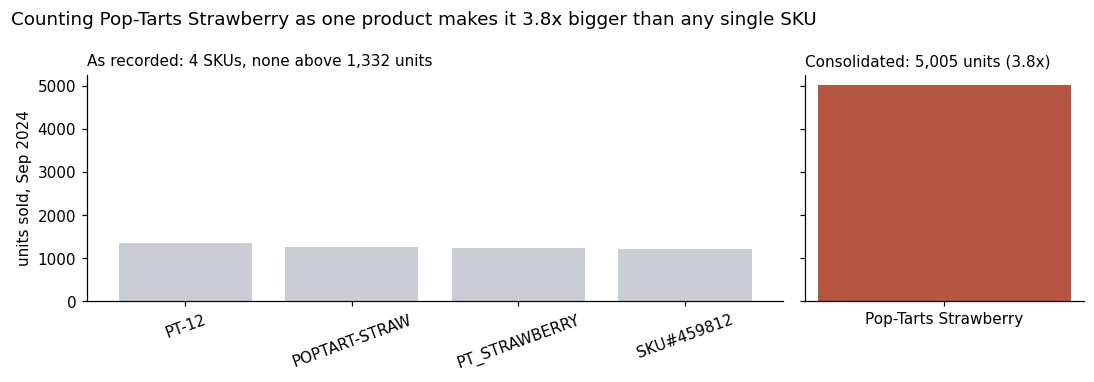

largest Pop-Tarts Strawberry SKU ranks #8 of 45 SKUs
Pop-Tarts Strawberry as one product ranks #2 of 20 products


In [12]:
family = sku_map.groupby('product')['sku'].size().idxmax()
fam = tx[tx['product'] == family]
fragmented = fam.groupby('sku')['quantity'].sum().sort_values(ascending=False)
combined = fragmented.sum()
multiple = combined / fragmented.max()

sku_rank = tx.groupby('sku')['quantity'].sum().rank(ascending=False)[fragmented.index[0]]
prod_rank = tx.groupby('product')['quantity'].sum().rank(ascending=False)[family]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True, gridspec_kw={'width_ratios': [len(fragmented), 1.6]})
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title(f'As recorded: {len(fragmented)} SKUs, none above {fragmented.max():,} units', fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar([family], [combined], color='#b4553f')
axes[1].set_title(f'Consolidated: {combined:,} units ({multiple:.1f}x)', fontsize=10, loc='left')
axes[0].set_ylabel('units sold, Sep 2024')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
fig.suptitle(f'Counting {family} as one product makes it {multiple:.1f}x bigger than any single SKU', x=0.01, ha='left', fontsize=12)
plt.tight_layout()
plt.show()

print(f'largest {family} SKU ranks #{sku_rank:.0f} of {tx["sku"].nunique()} SKUs')
print(f'{family} as one product ranks #{prod_rank:.0f} of {tx["product"].nunique()} products')

In [13]:
before = tx.groupby('sku')['quantity'].sum().nlargest(5).rename('units').to_frame()
after = tx.groupby('product')['quantity'].sum().nlargest(5).rename('units').to_frame()
print('top 5 before consolidation (by SKU):')
print(before)
print()
print('top 5 after consolidation (by product):')
print(after)

top 5 before consolidation (by SKU):
           units
sku             
WTR_24PK    1758
WATER24PK   1657
WTR-24      1622
BATT-100    1432
BAT-AA4     1427

top 5 after consolidation (by product):
                       units
product                     
Bottled Water 24-Pack   5037
Pop-Tarts Strawberry    5005
AA Batteries 4-Pack     4154
LED Flashlight          2814
Emergency Candles       2546


**Finding:** Strawberry Pop-Tarts were split across 4 SKUs (PT-12, SKU#459812, POPTART-STRAW, PT_STRAWBERRY) with about 1,200-1,330 units each. On a SKU report the biggest one ranks **#8 of 45** and never makes a top-5 list. Consolidated, Pop-Tarts is **5,005 units, 3.8x any single SKU, and the #2 product in the stores**, just behind bottled water (5,037).

The SKU top 5 is also misleading the other way: three of its five rows are the same product (water). Without consolidation, a planner would see water three times and miss Pop-Tarts entirely, even though it had the largest surge of anything we sell.

## 7. Q3 Weather correlation

Each store's daily units are divided by that store's own Sep 1-14 average so big and small stores are comparable.
Then we correlate that index with the day's max wind gust, and shift the weather by -3 to +3 days to see whether buying leads or follows the storm.
A positive lag means sales on day *t* are compared to weather on day *t + lag*.

correlation of sales index with max gust, by lag (days):
-3   -0.21
-2   -0.12
-1    0.01
 0    0.18
 1    0.50
 2    0.71
 3    0.56
dtype: float64


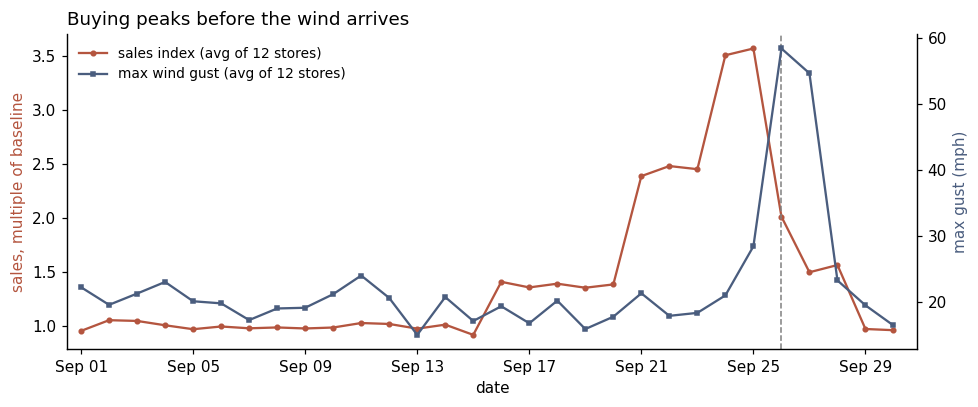

In [14]:
sw = sw.sort_values(['store_id', 'date'])
store_base = sw[sw['date'] <= BASE_END].groupby('store_id')['units'].mean()
sw['units_index'] = sw['units'] / sw['store_id'].map(store_base)

lags = range(-3, 4)
lag_corr = {}
for k in lags:
    future = sw.groupby('store_id')['max_gust_mph'].shift(-k)
    lag_corr[k] = sw['units_index'].corr(future)
lag_corr = pd.Series(lag_corr)
print('correlation of sales index with max gust, by lag (days):')
print(lag_corr.round(2))

statewide = sw.groupby('date')[['units_index', 'max_gust_mph', 'precip_in']].mean()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(statewide.index, statewide['units_index'], marker='o', ms=3, color='#b4553f', label='sales index (avg of 12 stores)')
ax.set_ylabel('sales, multiple of baseline', color='#b4553f')
ax2 = ax.twinx()
ax2.plot(statewide.index, statewide['max_gust_mph'], marker='s', ms=3, color='#4a5d7e', label='max wind gust (avg of 12 stores)')
ax2.set_ylabel('max gust (mph)', color='#4a5d7e')
ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
ax.set_title('Buying peaks before the wind arrives', loc='left', fontsize=12)
ax.set_xlabel('date')
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=range(1, 31, 4)))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_xlim(pd.Timestamp('2024-08-31 12:00'), pd.Timestamp('2024-09-30 20:00'))
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, fontsize=9, loc='upper left')
ax.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)
plt.tight_layout()
plt.show()

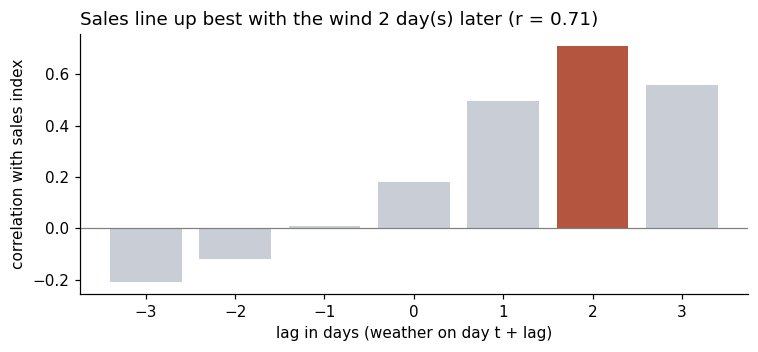

same-day correlation, sales index vs precipitation: -0.16


In [15]:
fig, ax = plt.subplots(figsize=(7, 3.3))
bars = ax.bar(lag_corr.index, lag_corr.values, color=['#b4553f' if k == lag_corr.idxmax() else '#c9cdd6' for k in lag_corr.index])
ax.axhline(0, color='gray', lw=0.8)
ax.set_title(f'Sales line up best with the wind {lag_corr.idxmax()} day(s) later (r = {lag_corr.max():.2f})', loc='left', fontsize=12)
ax.set_xlabel('lag in days (weather on day t + lag)')
ax.set_ylabel('correlation with sales index')
ax.set_xticks(list(lag_corr.index))
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print('same-day correlation, sales index vs precipitation:', round(sw['units_index'].corr(sw['precip_in']), 2))

**Finding:** All 360 store-days (12 stores x 30 days) joined one-to-one with weather in local time.

Same-day weather barely explains sales (r = 0.18 with max gust, -0.16 with rain). The relationship is strongest when sales are compared with **the wind two days later (r = 0.71)**. Buying peaked Sep 24-25, when gusts were still around 20-30 mph, while the strongest gusts (about 58 mph averaged across stores) came on Sep 26-27, when sales were already falling. People buy on the forecast, not on the weather outside.

Caveat: this is one storm and 30 days, and the 12 stores are not independent (they all saw the same forecast), so treat r = 0.71 as describing this event, not as a forecasting model.

## 8. Q4 Stores and geography

Distance is measured from each store to the approximate landfall point near Perry, FL (30.0N, 83.8W).
Surge multiple is average daily units on Sep 21-25 over the Sep 1-14 average. Every store has about 2,000 transactions, so no store's number rests on a tiny sample.

In [16]:
LANDFALL_LAT, LANDFALL_LON = 30.0, -83.8

def miles_between(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))

store_daily = tx.groupby(['store_id', 'date'])['quantity'].sum().unstack(0)
by_store = stores.set_index('store_id')[['city', 'region', 'latitude', 'longitude']].copy()
by_store['miles_to_landfall'] = miles_between(by_store['latitude'], by_store['longitude'], LANDFALL_LAT, LANDFALL_LON).round(0)
by_store['baseline_units_per_day'] = store_daily.loc[BASE_START:BASE_END].mean().round(1)
by_store['surge_units_per_day'] = store_daily.loc['2024-09-21':'2024-09-25'].mean().round(1)
by_store['surge_multiple'] = (by_store['surge_units_per_day'] / by_store['baseline_units_per_day']).round(2)
by_store['transactions'] = tx['store_id'].value_counts()
by_store = by_store.drop(columns=['latitude', 'longitude']).sort_values('miles_to_landfall')

rho = by_store['miles_to_landfall'].corr(by_store['surge_multiple'], method='spearman')
print(f"surge multiple range: {by_store['surge_multiple'].min()}x to {by_store['surge_multiple'].max()}x across {len(by_store)} stores")
print(f'spearman rank correlation, distance vs surge: {rho:.2f}')
by_store

surge multiple range: 2.6x to 3.2x across 12 stores
spearman rank correlation, distance vs surge: -0.08


,city,region,miles_to_landfall,baseline_units_per_day,surge_units_per_day,surge_multiple,transactions
store_id,,,,,,,
FL-619,Tallahassee,Panhandle,42.0,86.4,257.4,2.98,1981
FL-078,Gainesville,North,92.0,92.1,256.2,2.78,2001
FL-412,Jacksonville,North,130.0,91.1,262.8,2.88,2028
FL-105,Tampa,West,163.0,91.8,278.6,3.03,2043
FL-445,St. Petersburg,West,169.0,95.9,272.8,2.84,2074
FL-156,Daytona Beach,East,176.0,95.2,268.8,2.82,2074
FL-302,Lakeland,Central,176.0,98.0,286.0,2.92,2123
FL-239,Orlando,Central,177.0,94.4,245.2,2.60,2010
FL-287,Kissimmee,Central,186.0,91.0,256.2,2.82,2053


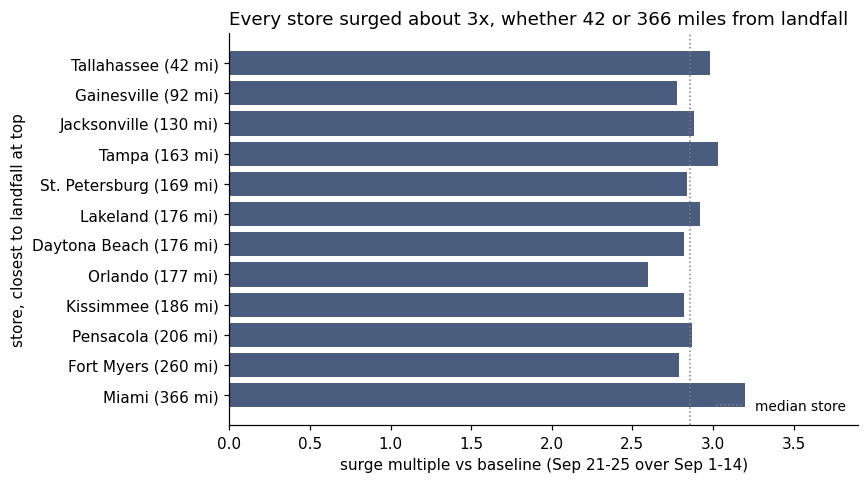

In [17]:
plot_df = by_store.sort_values('miles_to_landfall', ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(plot_df['city'] + ' (' + plot_df['miles_to_landfall'].astype(int).astype(str) + ' mi)', plot_df['surge_multiple'], color='#4a5d7e')
ax.axvline(plot_df['surge_multiple'].median(), ls=':', color='gray', lw=1, label='median store')
ax.set_title(f"Every store surged about 3x, whether {plot_df['miles_to_landfall'].min():.0f} or {plot_df['miles_to_landfall'].max():.0f} miles from landfall", loc='left', fontsize=12)
ax.set_xlabel('surge multiple vs baseline (Sep 21-25 over Sep 1-14)')
ax.set_ylabel('store, closest to landfall at top')
ax.set_xlim(0, 3.9)
ax.legend(frameon=False, fontsize=9, loc='lower right')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**Finding:** **There is no distance gradient.** Every store surged between 2.6x and 3.2x, and the rank correlation between distance and surge is -0.08. Tallahassee, 42 miles from landfall, surged 2.98x. Miami, 366 miles away and the farthest store, surged the most at 3.20x. Orlando was lowest at 2.60x. Each store has about 2,000 transactions, so these differences are not small-sample noise, but they are small.

With 12 stores we report this as a table and a ranked bar chart, not a trend line. Our reading: the pre-storm buying was statewide, because the forecast and news coverage reached all of Florida, not only the path. Distance here is to the landfall point, not to the full storm track, which is a limitation.

## 9. Q5 Signal or artifact

Is the surge real, or something the data produced? We check it against a second system: the inventory database.
The database has its own problems, cleaned here in SQL and logged.

In [18]:
con = sqlite3.connect('../data/inventory_and_sales.db')

FIX_DATE = "CASE WHEN date LIKE '____-__-__' THEN date ELSE substr(date, 1, 4) || '-' || substr(date, 5, 2) || '-' || substr(date, 7, 2) END"

checks = pd.read_sql(f'''
SELECT
  (SELECT COUNT(*) FROM daily_sales_summary WHERE date NOT LIKE '____-__-__') AS summary_compact_dates,
  (SELECT COUNT(*) FROM daily_sales_summary WHERE total_units != CAST(total_units AS INTEGER)) AS summary_half_units,
  (SELECT COUNT(*) FROM (SELECT {FIX_DATE} d, store_id, category FROM daily_sales_summary GROUP BY 1, 2, 3 HAVING COUNT(*) > 1)) AS summary_dup_keys,
  (SELECT COUNT(*) FROM inventory_levels WHERE units_on_order IS NULL) AS inventory_null_on_order,
  (SELECT COUNT(DISTINCT sku) FROM inventory_levels) AS inventory_skus
''', con)
checks.T.rename(columns={0: 'rows'})

,rows
summary_compact_dates,218
summary_half_units,76
summary_dup_keys,0
inventory_null_on_order,626
inventory_skus,49


In [19]:
unknown = sorted(set(pd.read_sql('SELECT DISTINCT sku FROM inventory_levels', con)['sku']) - set(sku_map['sku']))
print('inventory SKUs not in the catalog:', unknown)

log('db summary', 'normalized 20240901-style dates to 2024-09-01 in SQL', checks.loc[0, 'summary_compact_dates'])
log('db summary', 'kept half-unit totals (e.g. 71.5) as is, flagged as an artifact; too small to move daily totals', checks.loc[0, 'summary_half_units'])
n_unknown = pd.read_sql(f"SELECT COUNT(*) n FROM inventory_levels WHERE sku IN ({','.join('?' * len(unknown))})", con, params=unknown).loc[0, 'n']
log('db inventory', f'dropped rows for SKUs not in the catalog ({", ".join(unknown)})', n_unknown)

db_daily = pd.read_sql(f'''
SELECT {FIX_DATE} AS date, SUM(total_units) AS db_units, SUM(total_revenue) AS db_revenue
FROM daily_sales_summary
GROUP BY 1
ORDER BY 1
''', con, parse_dates=['date'])

xcheck = db_daily.merge(tx.groupby('date').agg(tx_units=('quantity', 'sum'), tx_revenue=('revenue', 'sum')).reset_index(),
                        on='date', how='inner', validate='one_to_one')
xcheck['ratio'] = xcheck['db_units'] / xcheck['tx_units']
assert len(xcheck) == 30

print('days matched:', len(xcheck))
print('db units / transaction units: mean', round(xcheck['ratio'].mean(), 2), '| min', round(xcheck['ratio'].min(), 2), '| max', round(xcheck['ratio'].max(), 2))
print('correlation of daily totals:', round(xcheck['db_units'].corr(xcheck['tx_units']), 3))

inventory SKUs not in the catalog: ['LEGACY-PT', 'MISC-001', 'OLD-BATT-50', 'UNKNOWN-99']
days matched: 30
db units / transaction units: mean 5.12 | min 4.18 | max 6.18
correlation of daily totals: 0.991


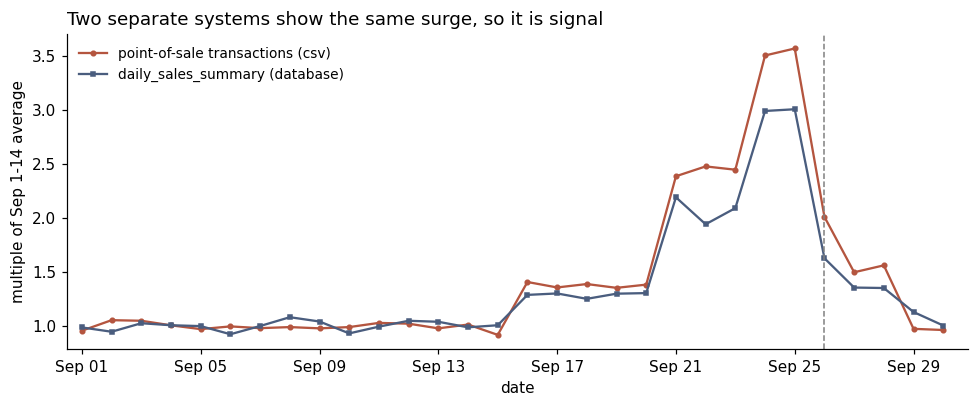

,db_units,tx_units,ratio
category,,,
Emergency,26332.5,16678,1.58
Grocery,20568.0,6357,3.24
Entertainment,24070.0,4250,5.66
Breakfast,30700.0,5005,6.13
Household,22809.0,3413,6.68
Baby,20961.5,2995,7.00
Electronics,23792.5,3047,7.81
Alcohol,24246.5,2493,9.73
Snacks,19988.5,1876,10.65


In [20]:
xi = xcheck.set_index('date')[['db_units', 'tx_units']]
xi = xi / xi.loc[BASE_START:BASE_END].mean()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(xi.index, xi['tx_units'], marker='o', ms=3, color='#b4553f', label='point-of-sale transactions (csv)')
ax.plot(xi.index, xi['db_units'], marker='s', ms=3, color='#4a5d7e', label='daily_sales_summary (database)')
ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
ax.set_title('Two separate systems show the same surge, so it is signal', loc='left', fontsize=12)
ax.set_xlabel('date')
ax.set_ylabel('multiple of Sep 1-14 average')
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=range(1, 31, 4)))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_xlim(pd.Timestamp('2024-08-31 12:00'), pd.Timestamp('2024-09-30 20:00'))
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

db_cat = pd.read_sql('SELECT category, SUM(total_units) AS db_units FROM daily_sales_summary GROUP BY category', con).set_index('category')
db_cat['tx_units'] = tx.groupby('category')['quantity'].sum()
db_cat['ratio'] = (db_cat['db_units'] / db_cat['tx_units']).round(2)
db_cat.sort_values('ratio')

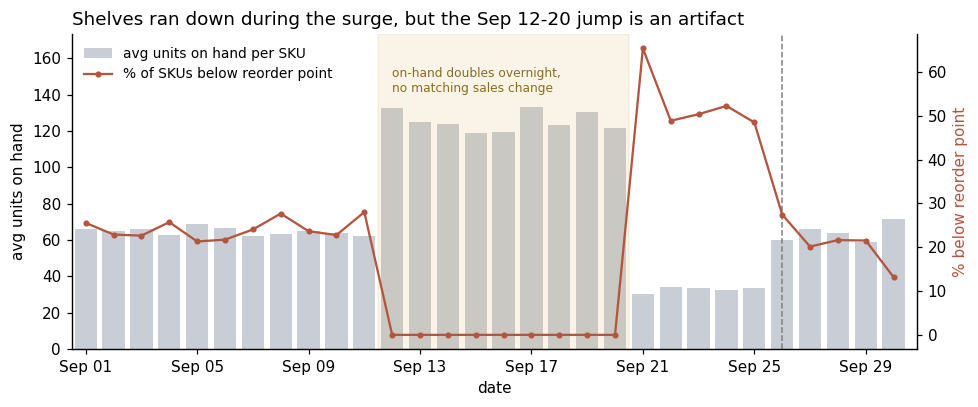

,rows_sampled,avg_on_hand,pct_below_reorder
date,,,
2024-09-09,131,65.0,23.7
2024-09-10,136,64.2,22.8
2024-09-11,132,62.4,28.0
2024-09-12,133,132.7,0.0
2024-09-13,135,125.1,0.0
2024-09-14,134,124.1,0.0
2024-09-15,131,118.8,0.0
2024-09-16,130,119.6,0.0
2024-09-17,132,133.2,0.0


In [21]:
inv = pd.read_sql(f'''
SELECT date,
       COUNT(*) AS rows_sampled,
       AVG(units_on_hand) AS avg_on_hand,
       AVG(CASE WHEN units_on_hand < reorder_point THEN 1.0 ELSE 0 END) * 100 AS pct_below_reorder
FROM inventory_levels
WHERE sku NOT IN ({','.join('?' * len(unknown))})
GROUP BY date
ORDER BY date
''', con, params=unknown, parse_dates=['date']).set_index('date')

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(inv.index, inv['avg_on_hand'], color='#c9cdd6', label='avg units on hand per SKU')
ax.set_ylabel('avg units on hand')
ax2 = ax.twinx()
ax2.plot(inv.index, inv['pct_below_reorder'], marker='o', ms=3, color='#b4553f', label='% of SKUs below reorder point')
ax2.set_ylabel('% below reorder point', color='#b4553f')
ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
ax.axvspan(pd.Timestamp('2024-09-11 12:00'), pd.Timestamp('2024-09-20 12:00'), color='#d9a441', alpha=0.12)
ax.set_ylim(0, inv['avg_on_hand'].max() * 1.3)
ax.annotate('on-hand doubles overnight,\nno matching sales change', xy=(pd.Timestamp('2024-09-12'), inv['avg_on_hand'].max() * 1.06), fontsize=8, color='#8a6d1f')
ax.set_title('Shelves ran down during the surge, but the Sep 12-20 jump is an artifact', loc='left', fontsize=12)
ax.set_xlabel('date')
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=range(1, 31, 4)))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_xlim(pd.Timestamp('2024-08-31 12:00'), pd.Timestamp('2024-09-30 20:00'))
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, fontsize=9, loc='upper left')
ax.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)
plt.tight_layout()
plt.show()

inv.round(1).loc['2024-09-09':'2024-09-27']

**Finding:** **The surge is signal.** The database's `daily_sales_summary` is a separate system from the point-of-sale file, and its daily totals run at a steady 5.1x the transaction file (4.2x to 6.2x on every day) with a correlation of 0.991. Indexed to baseline, the two curves rise, peak and fall on the same days.

Two things in the database are artifacts and should not be used:

- **Category totals.** The database splits units almost evenly across categories (20,000-31,000 each), while the transactions put Emergency at 16,678 units and Health at 1,783. The ratio ranges from 1.6x to 13.3x by category, so the database is fine for daily totals but not for category mix.
- **Inventory on Sep 12-20.** Average units on hand doubled overnight (62 to 133) with zero SKUs below reorder point, and no matching change in sales or units on order. That looks like a recording or unit change, not real stock.

The drawdown after that is real: from **Sep 21-25, on-hand fell to about 33 units per SKU and 49-65% of sampled SKUs were below their reorder point**, exactly when demand surged. Smaller issues fixed or flagged: 218 compact dates, 76 half-unit totals, 355 rows for 4 SKUs not in the catalog, and 626 missing `units_on_order` values. The inventory table also samples about 12 SKUs per store per day, not the full assortment.

## 10. Recommendations

1. **Trigger on the forecast, not the weather.** Demand started climbing 10 days out and peaked 1-2 days before landfall, two days ahead of the worst wind. Storm stock should be in stores at least 5 days before landfall. In this storm, half the sampled SKUs were already below reorder point 5 days out.
2. **Stock every Florida store, not just the path.** The surge was about 3x everywhere, from Tallahassee to Miami. Allocating by distance to the forecast track would have shorted stores like Miami and Tampa.
3. **Plan Pop-Tarts as a storm item.** At 9.2x baseline it moved more than water or flashlights. Merge its 4 SKUs in the product master so it shows up in reports.
4. **Fix the data before the next storm.** Standardize store ids and SKUs at the source, audit the Sep 12-20 inventory jump, and do not use the database's category split until it matches point-of-sale data.

In [22]:
pd.DataFrame(decisions)

,step,decision,rows_touched
0,duplicates,dropped exact duplicate rows (same transaction_id and every other column),30
1,store_id,"strip, uppercase, _ -> -, FL239 -> FL-239",4345
2,unit_price,"removed $ and spaces, converted text to float",4329
3,quantity,"dropped negative quantities (returns, not demand)",130
4,timestamp,parsed 5 formats as local store time; dropped rows with no timestamp (blank/NULL/N/A/NaN),881
5,category,mapped 37 spellings onto 10 categories (names match the inventory db),18009
6,stores,"dropped duplicate store rows after fixing store_id (FL239, FL_287)",2
7,stores,"state Florida / Fla. -> FL, stripped region",3
8,stores,filled missing lat/lon for FL-619 Tallahassee with city center coordinates,1
9,sku,mapped 45 SKUs to 20 canonical products by keyword on the catalog name,24521
